# STATE Codex r2 — 03 Expected perturbation magnitude

Run All invokes the source pipeline with `--force`: it recalculates the selected investigation from verified public inputs. Existing downloads can be reused after verification; derived result tables are not a substitute for the default calculation. The completed execution runs on exxact05. Use the documented Python environment and allow the source downloads, CPU time and disk space on a cold run.

The notebooks distinguish measured outcomes from investigations that originally stopped before scoring. For those stops, the reproduced objects are input levels, eligibility, resource diagnostics and the recorded decision; no performance curve is invented. Original results are comparison targets and historical evidence only. Reconstructed choices and numerical differences remain explicit.

See the [original report](../originals/REPORT.md), [candidate ledger](../originals/supporting/audit/candidate_axis_ledger.csv), [public sources](../methods/sources.json) and [pipeline](../methods/run_pipeline.py).

## 1. Data acquisition

A2 uses the same pinned Replogle vectors and original four-context availability. The external A2e attempt uses official Tahoe test lists and its original public pseudobulk inventory. The original unfinished scan is retained as a stopping diagnostic, not treated as a completed prediction study.

In [1]:
from pathlib import Path
import importlib.util,json,sys
import numpy as np
import pandas as pd
from IPython.display import display,JSON,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'methods/replogle.py').is_file() and (p/'originals/REPORT.md').is_file())
spec=importlib.util.spec_from_file_location('state_codex_r2_notebook',ROOT/'notebooks/shared.py')
wf=importlib.util.module_from_spec(spec);spec.loader.exec_module(wf)
pd.set_option('display.max_colwidth',100);pd.set_option('display.max_rows',100)
manifest=wf.read_json(ROOT,'methods/sources.json')
sources=pd.DataFrame(manifest['inputs'])
display(sources[['path','bytes','sha256','url']])
if manifest.get('remote_observations'):
    display(Markdown('**Pinned observation-only source objects used for Replogle cell counts**'))
    display(pd.DataFrame(manifest['remote_observations']))
wf.source_functions(ROOT,'methods/acquire.py',['main'])
print('Manifest public input records:',len(sources))
print('The next cell executes actual source calculation for this investigation.')


,path,bytes,sha256,url
0,metadata/generalization.toml,150875,eac16fb06052dec9d6842dfae04d5ca693b847e3432f719a975adce205707783,https://raw.githubusercontent.com/ArcInstitute/state/da4178c930dc917dac6b56faf10a33e21bd8e905/st...
1,metadata/depmap_24q4_protein_coding_tpm_logp1.csv,506628654,2a71dc94110efcc0221eae821bb93a9f03b54bea16f005818911a09d33383d56,https://ndownloader.figshare.com/files/51065489
2,metadata/depmap_24q4_model.csv,645696,b7a0c1385e6cef30132b56aff61f1261d11e3f490490b355c430d32ee0dbdcfa,https://ndownloader.figshare.com/files/51065297
3,metadata/hpa_rna_celline.tsv.zip,205861141,e5b11779308c2720cfe89d9cb19932ad4c0c3fea0fa37e8c61a14d501995852a,https://www.proteinatlas.org/download/tsv/rna_celline.tsv.zip
4,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_pred_de.csv,344243692,230ac1f1f8342d0c7f563166b6e8f9afeae6a02a62d0b737fda64168dde49ba0,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
5,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_real_de.csv,343530568,a367d89432c430f6bef3d3efd23c0a543144c1c55bb94e64c818c97de2cbd1dd,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
6,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv,528013,eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
7,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_pred_de.csv,380905134,fd3422f18087eaf8357112bc0fd87faa8f95ed2a9ad95f0e7c4107d52754a9ca,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
8,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_real_de.csv,380988038,68fcb087841310e0e435b1bf63f1dbd69fc73c849d31a288f01d9d7ce40982ff,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
9,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv,568100,372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...


**Pinned observation-only source objects used for Replogle cell counts**

,path,url,bytes,sha256,evidence
0,ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,3079506036,6951f4bffb532950c447e8dc300b2f42ab381c854273327f8cd38b84cfa4eb42,Pinned original release; observation-only range extraction
1,ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,3012265108,9df1a21e3b159fa3900a32dd8bd6b4d6dd8750838014d1d3997932d7cedc9673,Pinned original release; observation-only range extraction
2,ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,1577727376,75f79feff37c4334559ea88c1e2a27acd306eb7dee5a2e25f37c4860014ca2b9,Pinned original release; observation-only range extraction
3,ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/adata_real.h5ad,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...,2837025870,f3363768db24b7eee9cb55507443366f8e15b6f9e5731ac415f533b757a5b5b1,Pinned original release; observation-only range extraction


**Executed implementation:** `methods/acquire.py::main`

def main():
    ap=argparse.ArgumentParser();ap.add_argument('--root',type=Path,required=True);ap.add_argument('--reuse',type=Path);ap.add_argument('--manifest-only',action='store_true');ap.add_argument('--refresh-manifest',action='store_true');a=ap.parse_args();r=a.root.resolve()
    p=r/'methods/sources.json';m=json.loads(p.read_text()) if p.exists() and not a.refresh_manifest else manifest(r)
    if a.manifest_only:return
    reuse={}
    if a.reuse:
        for x in json.loads((a.reuse/'methods/sources.json').read_text())['inputs']:reuse[x['sha256']]=a.reuse/'inputs'/x['path']
    def one(x):
        p=r/'inputs'/x['path'];p.parent.mkdir(parents=True,exist_ok=True)
        if p.exists() and p.stat().st_size==x['bytes'] and sha(p)==x['sha256']:return {**x,'verified':True,'route':'existing'}
        q=reuse.get(x['sha256'])
        if q and q.exists() and q.stat().st_size==x['bytes'] and sha(q)==x['sha256']:
            p.symlink_to(q.resolve());print('REUSE',x['path'],flush=True);return {**x,'verified':True,'route':'identical_sha256_symlink'}
        tmp=p.with_name(p.name+'.part')
        for attempt in range(4):
            try:
                with urllib.request.urlopen(x['url'],timeout=180) as src,tmp.open('wb') as dst:
                    for b in iter(lambda:src.read(8*1024*1024),b''):dst.write(b)
                assert tmp.stat().st_size==x['bytes'],(tmp.stat().st_size,x['bytes'])
                assert sha(tmp)==x['sha256'],'Source checksum mismatch'
                os.replace(tmp,p);print('VERIFIED',x['path'],x['bytes'],flush=True)
                return {**x,'verified':True,'route':'public_download'}
            except Exception:
                if attempt==3:raise
                time.sleep(2*(attempt+1))
    with concurrent.futures.ThreadPoolExecutor(max_workers=2) as pool:done=list(pool.map(one,m['inputs']))
    (r/'inputs/DOWNLOAD_RECEIPT.json').write_text(json.dumps(dict(source_manifest_sha256=sha(r/'methods/sources.json'),inputs=done),indent=2)+'\n')

Manifest public input records: 49
The next cell executes actual source calculation for this investigation.


## 2. Processing

Rebuild expected response magnitude from the other three contexts, recompute the discovery scores, and check disjoint confirmation availability. The pipeline separately reconstructs the external Tahoe cohort and input diagnostics; it does not invent the unfinished A2e response aggregate.

In [2]:
pipeline=wf.run_pipeline(ROOT,'magnitude')
wf.source_functions(ROOT,'methods/replogle.py',['scores','analyze'])
units=wf.read_csv(ROOT,'computed/replogle/magnitude_units.csv')
eligibility=wf.read_csv(ROOT,'computed/replogle/A2_eligibility.csv')
display(units[['context','perturbation','expected_rms','weakness','magnitude_level','state_se']].head(12))
wf.source_receipts(ROOT,['replogle_scores','replogle_analysis','closures'])


Calculating the original source workflow for magnitude ; source files are verified before reuse.


Calculating from source inputs: replogle_axis


Calculating from source inputs: replogle_scores


REPL DE ST-SE-Replogle k562 real


REPL DE ST-SE-Replogle k562 pred


REPL DE ST-SE-Replogle jurkat real


... (28 outputs left out)

**Calculated stage:** replogle_analysis

<IPython.core.display.JSON object>

**Calculated stage:** closures

<IPython.core.display.JSON object>

## 3. Axis

Expected RMS is calculated exclusively from training-context real effects; weakness is its negative log1p transform. The report’s residual-correlation transformation is not fully specified, so both explicitly labeled correlation calculations remain in the summary. They are not searched to select the reported value.

In [3]:
display(JSON(wf.read_json(ROOT,'computed/replogle/magnitude_summary.json')))
display(JSON(wf.read_json(ROOT,'originals/supporting/audit/axis/frozen_axis_A2.json')))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

## 4. Levels and eligibility

Discovery levels are stable equal-count strata within context, strongest expected response to weakest, with documented lexical ties. Confirmation excludes the original balanced discovery perturbations and requires a complete four-context panel. Eligibility is recalculated from the original release membership.

In [4]:
display(units.groupby(['context','magnitude_level']).agg(units=('perturbation','size'),min_expected_rms=('expected_rms','min'),max_expected_rms=('expected_rms','max')))
display(eligibility)
print('Disjoint candidates:',int(eligibility.confirmation_candidate.sum()))
print('Eligible disjoint candidates:',int(eligibility.confirmation_eligible.sum()))
display(wf.read_csv(ROOT,'computed/replogle/released_condition_availability.csv').head(12))


units  min_expected_rms  max_expected_rms
context magnitude_level                                           
hepg2   1                  128          0.567326          0.979016
        2                  128          0.442380          0.564969
        3                  127          0.350855          0.442360
        4                  128          0.274610          0.350474
        5                  127          0.101615          0.274352
jurkat  1                  128          0.622774          1.173102
        2                  128          0.475942          0.619354
        3                  127          0.384956          0.475651
        4                  128          0.326022          0.384914
        5                  127          0.119322          0.326021
k562    1                  128          0.636786          1.191528
        2                  128          0.493637          0.635852
        3                  127          0.397295          0.493428
        4                  128          0.332671          0.396287
        5                  127          0.093471          0.332364
rpe1    1                  128          0.478187          0.917558
        2                  128          0.392323          0.477231
        3                  127          0.342415          0.392013
        4                  128          0.299153          0.342319
        5                  127          0.116239          0.299104

,perturbation,discovery,confirmation_candidate,k562_real,k562_pred,jurkat_real,jurkat_pred,hepg2_real,hepg2_pred,rpe1_real,rpe1_pred,confirmation_eligible
0,AAAS,True,False,True,True,True,True,True,True,True,True,False
1,AAMP,False,True,True,True,True,True,False,False,False,False,False
2,AAR2,False,True,False,False,True,True,True,True,False,False,False
3,AARS,True,False,True,True,True,True,True,True,True,True,False
4,AARS2,False,True,True,True,True,True,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
2018,ZNRD1,False,True,True,True,True,True,True,True,False,False,False
2019,ZRANB2,False,True,True,True,True,True,False,False,True,True,False
2020,ZRSR2,False,True,False,False,True,True,False,False,True,True,False
2021,ZW10,False,True,True,True,True,True,False,False,True,True,False


Disjoint candidates: 1385
Eligible disjoint candidates: 0


,model,context,kind,perturbation
0,ST-SE-Replogle,k562,real,AAAS
1,ST-SE-Replogle,k562,real,AAMP
2,ST-SE-Replogle,k562,real,AARS
3,ST-SE-Replogle,k562,real,AARS2
4,ST-SE-Replogle,k562,real,AASDHPPT
5,ST-SE-Replogle,k562,real,AATF
6,ST-SE-Replogle,k562,real,ABCB7
7,ST-SE-Replogle,k562,real,ABCE1
8,ST-SE-Replogle,k562,real,ABHD11
9,ST-SE-Replogle,k562,real,ABHD17A


## 5. Model / released scores

A2 discovery measurements are real recomputed unit scores. The original disjoint confirmation had no eligible units, so it has no outcome test. A2e’s879-gene mapping rows and1536-block partial reconciliation did not survive the handoff; their documented hashes/counts are historical evidence, not newly recomputed measurements.

In [5]:
wf.source_functions(ROOT,'methods/replogle.py',['de_matrix','row_spearman'])
closures=wf.read_json(ROOT,'computed/closures/closure_diagnostics.json')
display(JSON(closures['A2e']))
display(wf.read_csv(ROOT,'computed/tahoe/cohort.csv').head(12))
display(wf.read_csv(ROOT,'computed/closures/original_public_shard_inventory.csv'))


**Executed implementation:** `methods/replogle.py::de_matrix`

def de_matrix(p):
    d=pd.read_csv(p,usecols=['target','feature','fold_change','fdr']);d=d[d.target!='non-targeting'].copy()
    # Frozen definition is log2 official fold_change. Nonpositive entries are
    # excluded as nonfinite, rather than choosing a result-dependent pseudocount.
    d['lfc']=np.log2(d.fold_change.where(d.fold_change>0));d['significant']=(d.fdr<.05).astype(int)
    q=d.groupby(['target','feature'],sort=True).agg(lfc=('lfc','mean'),significant=('significant','max')).reset_index()
    mat=q.pivot(index='target',columns='feature',values='lfc');nd=q.groupby('target').significant.sum()
    return mat,nd

**Executed implementation:** `methods/replogle.py::row_spearman`

def row_spearman(a,b):
    out=[]
    for x,y in zip(a,b):
        f=np.isfinite(x)&np.isfinite(y)
        out.append(float(spearmanr(x[f],y[f]).statistic) if f.sum()>=20 else np.nan)
    return np.asarray(out)

<IPython.core.display.JSON object>

,context,drug,dose,unit,weakness,dose_level
0,C32,(R)-Verapamil (hydrochloride),0.05,uM,1.30103,3
1,C32,(R)-Verapamil (hydrochloride),0.50,uM,0.30103,2
2,C32,(R)-Verapamil (hydrochloride),5.00,uM,-0.69897,1
3,C32,(S)-Crizotinib,0.05,uM,1.30103,3
4,C32,(S)-Crizotinib,0.50,uM,0.30103,2
5,C32,(S)-Crizotinib,5.00,uM,-0.69897,1
6,C32,8-Hydroxyquinoline,0.05,uM,1.30103,3
7,C32,8-Hydroxyquinoline,0.50,uM,0.30103,2
8,C32,8-Hydroxyquinoline,5.00,uM,-0.69897,1
9,C32,APTO-253,0.05,uM,1.30103,3


,config,shards,bytes
0,cell_line_metadata,1,19040
1,drug_metadata,1,40475
2,expression_data,3388,337644770670
3,gene_metadata,1,1326799
4,obs_metadata,1,2293981573
5,pseudobulk_differential_expression,1026,88859715303
6,sample_metadata,1,65636


## 6. Curves, controls and diagnostics

The discovery curve and its perturbation-block uncertainty are recomputed. The zero-eligibility and unfinished external aggregation are the original confirmation diagnostics. No confirmation SPC is drawn where no original biological result existed.

**Executed implementation:** `methods/common.py::fisher`

def fisher(x):return np.arctanh(np.clip(np.asarray(x,float),-1+1e-7,1-1e-7))

**Executed implementation:** `methods/common.py::cluster_fit`

def cluster_fit(d,y,x,cluster,adjust=(),fixed=(),cluster_fixed=False,draws=10000,seed=20260715):
    """OLS and paired cluster-resampling percentile CI via exact sufficient stats.

    When cluster_fixed=True, first remove the cluster mean. Resampling duplicated
    clusters is equivalent to giving that cluster an integer frequency weight.
    Axis standardization is fixed on the original analyzed rows, not redefined
    within each bootstrap draw. No historical estimates enter this function.
    """
    cols=[y,x,cluster,*adjust,*fixed];d=d.dropna(subset=cols).copy()
    X=[np.ones(len(d)),zscore(d[x])];names=['intercept',x]
    for c in adjust:
        v=np.asarray(d[c],float)
        if np.std(v)>0:X.append(zscore(v));names.append(c)
    for c in fixed:
        for val in sorted(d[c].unique())[1:]:X.append((d[c]==val).astype(float).values);names.append(f'{c}={val}')
    X=np.column_stack(X);Y=d[y].to_numpy(float)
    groups=sorted(d[cluster].unique());codes=pd.Categorical(d[cluster],categories=groups).codes
    if cluster_fixed:
        for j in range(len(groups)):
            sel=codes==j;X[sel]-=X[sel].mean(axis=0);Y[sel]-=Y[sel].mean()
        X=X[:,1:];names=names[1:];axis_idx=0
    else:axis_idx=1
    gxx=np.zeros((len(groups),X.shape[1],X.shape[1]));gxy=np.zeros((len(groups),X.shape[1]))
    for j in range(len(groups)):
        sel=codes==j;gxx[j]=X[sel].T@X[sel];gxy[j]=X[sel].T@Y[sel]
    coefficient=np.linalg.lstsq(X,Y,rcond=None)[0];rng=np.random.default_rng(seed);boot=[]
    for start in range(0,draws,100):
        n=min(100,draws-start);w=rng.multinomial(len(groups),np.full(len(groups),1/len(groups)),size=n)
        xx=np.einsum('bg,gij->bij',w,gxx);xy=w@gxy
        for a,b in zip(xx,xy):boot.append(np.linalg.lstsq(a,b,rcond=None)[0][axis_idx])
    return dict(n=len(d),clusters=len(groups),coefficient=float(coefficient[axis_idx]),ci95=np.quantile(boot,[.025,.975]).tolist(),draws=draws,seed=seed,design_columns=names,cluster_fixed_effect=cluster_fixed,axis_standardization='population SD on all analyzed rows',coefficients=dict(zip(names,coefficient))),np.asarray(boot)

**Executed implementation:** `methods/common.py::curve`

def curve(d,level,score,cluster,draws=10000,seed=20260715):
    groups=sorted(d[cluster].unique());levels=sorted(d[level].unique());rng=np.random.default_rng(seed)
    w=rng.multinomial(len(groups),np.full(len(groups),1/len(groups)),size=draws);rows=[];boot={}
    for v in levels:
        q=d[d[level]==v];g=q.groupby(cluster)[score].agg(['sum','count']).reindex(groups,fill_value=0)
        b=(w@g['sum'].values)/(w@g['count'].values);boot[str(v)]=b
        rows.append(dict(level=v,n=len(q),clusters=q[cluster].nunique(),mean=q[score].mean(),ci_low=np.quantile(b,.025),ci_high=np.quantile(b,.975)))
    return pd.DataFrame(rows),boot

,fit,n,clusters,coefficient,ci95,draws,seed,design_columns,cluster_fixed_effect,axis_standardization
0,fit,2552,638,-0.107892,"[-0.11390799290616625, -0.10180329374391955]",10000,20260715,"[intercept, weakness, context=jurkat, context=k562, context=rpe1]",False,population SD on all analyzed rows


,level,n,clusters,mean,ci_low,ci_high
0,1,512,162,0.277312,0.260672,0.293289
1,2,512,228,0.138142,0.122950,0.153380
2,3,508,256,0.065694,0.055989,0.075724
3,4,512,251,0.027799,0.020946,0.034897
4,5,508,200,0.021129,0.014697,0.027738


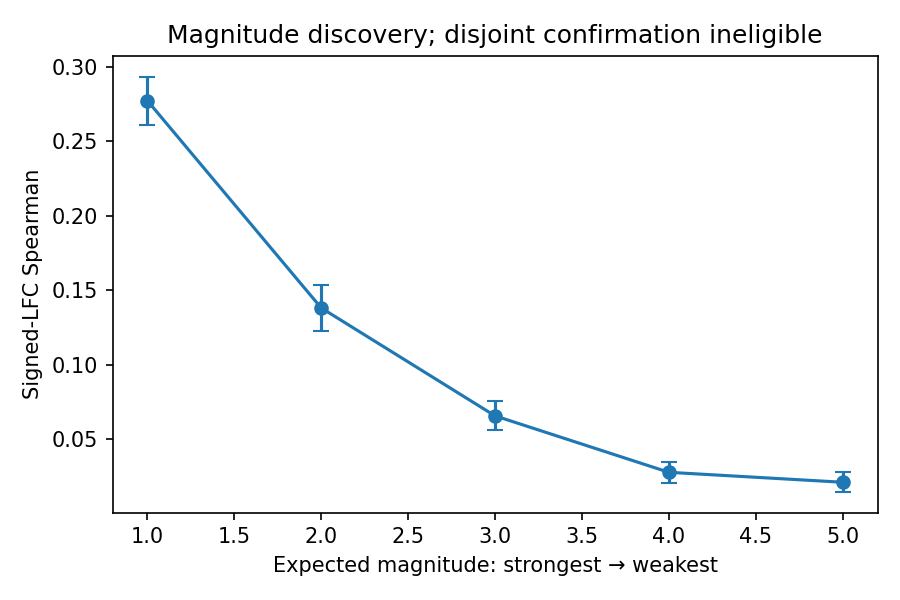

**Executed implementation:** `methods/closures.py::run`

def run(root):
    out=root/'computed/closures';out.mkdir(parents=True,exist_ok=True)
    co=pd.read_csv(root/'computed/tahoe/cohort.csv');counts=pd.read_csv(root/'computed/tahoe/condition_controls.csv')
    d=co.merge(counts,on=['context','drug','dose'],validate='one_to_one',how='left');d['sampling_weakness']=-np.log1p(d.n_treated)
    order=d.dropna(subset=['sampling_weakness']).sort_values(['sampling_weakness','context','drug','dose'],kind='mergesort').index
    d.loc[order,'support_level']=np.floor(np.arange(len(order))*5/len(order)).astype(int)+1
    d.to_csv(out/'secondary_input_axes.csv',index=False)
    support=d.groupby('support_level').agg(units=('drug','size'),mean_treated=('n_treated','mean'),min_treated=('n_treated','min'),max_treated=('n_treated','max')).reset_index();support.to_csv(out/'support_levels.csv',index=False)
    records=json.loads((root/'methods/sources.json').read_text())['inputs'];inv=[]
    for r in records:
        if not r['path'].startswith('ST-') or not r['path'].endswith('_results.csv'):continue
        model,path=r['path'].split('/',1);dataset='Replogle' if 'Replogle' in model else 'Tahoe';modality='genetic CRISPRi' if dataset=='Replogle' else 'chemical drug'
        inv.append(dict(dataset=dataset,modality=modality,model=model,representation='SE' if '-SE-' in model else 'HVG',setting=path.split('/')[0],context=Path(path).name.removesuffix('_results.csv'),source_path=r['path'],source_sha256=r['sha256']))
    inv=pd.DataFrame(inv);inv.to_csv(out/'release_modality_assignments.csv',index=False)
    # Explicit algebraic identification check: modality is exactly the dataset
    # dummy. No prediction outcome or regression response is needed.
    dataset=(inv.dataset=='Tahoe').astype(float).values;modality=(inv.modality=='chemical drug').astype(float).values
    X=np.column_stack([np.ones(len(inv)),dataset,modality]);rank=int(np.linalg.matrix_rank(X));assert np.array_equal(dataset,modality)
    historical=json.loads((root/'originals/supporting/audit/results/tahoe_prospective_summary.json').read_text())
    manifest=json.loads((root/'originals/supporting/audit/data/prospective/tahoe_pseudobulk_parquet_manifest.json').read_text())
    summary=pd.DataFrame(manifest['parquet_files']).groupby('config').agg(shards=('filename','size'),bytes=('size','sum')).reset_index();summary.to_csv(out/'original_public_shard_inventory.csv',index=False)
    status=dict(A2e=dict(original_status='Unscored; original prospective pseudobulk reconciliation did not finish',reconstructed_cohort_drugs=int(co.drug.nunique()),reconstructed_cohort_units=len(co),current_work='Original cohort and source inventory reconstructed; original partial block map was not included in surviving handoff, so1536-block reconciliation is historical-only.',historical_retained_summary=historical,original_879_gene_mapping_status='Original mapping hash/definition survives; mapping rows were not included in this handoff. No879-gene outcome analysis was originally completed.'),A3=dict(original_status='Unscored dependency closure',reconstructed_input_level_counts=support.to_dict('records'),outcome_test_performed=False),A5=dict(original_status='Unscored A2e-dependent dose test; distinct from completed A10',reconstructed_dose_levels=sorted(co.dose.unique().tolist()),outcome_test_performed=False),A6=dict(original_status='Unscored A2e-dependent family interaction',release_assignment_rows=len(inv),outcome_test_performed=False),A4=dict(original_status='Nonidentifiable modality contrast',design_columns=['intercept','Tahoe dataset','chemical modality'],design_rank=rank,number_columns=3,exact_modality_dataset_collinearity=True,outcome_test_performed=False))
    dump(out/'closure_diagnostics.json',status)
    sources=[root/'computed/tahoe/cohort.csv',root/'computed/tahoe/condition_controls.csv',root/'methods/sources.json',root/'originals/supporting/audit/data/prospective/tahoe_pseudobulk_parquet_manifest.json',root/'originals/supporting/audit/axis/frozen_axis_secon

In [6]:
wf.source_functions(ROOT,'methods/common.py',['fisher','cluster_fit','curve'])
result=wf.read_json(ROOT,'computed/replogle/magnitude_summary.json')
wf.show_fits(result);display(wf.read_csv(ROOT,'computed/replogle/magnitude_curve.csv'))
wf.show_curve(ROOT,'magnitude_curve.png')
wf.source_functions(ROOT,'methods/closures.py',['run'])


## 7. Historical result and decision

The original agent treated expected magnitude as a strong discovery nomination. Same-atlas confirmation remained structurally unavailable, and external transport stopped at input aggregation. Those decisions are preserved; the code does not relax their original eligibility or fill the absent partial artifacts with invented values.

In [7]:
wf.original_rows(ROOT,['A2','A2e'])
print('Reconstructed: original discovery calculations, release eligibility, Tahoe cohort and resource inventory.')
print('Historical-only partial diagnostics:879mapping count/hash and1536-block progress; original data rows were absent from the handoff.')


,candidate_id,axis,status,decision_reason,next_action
2,A2,training-panel expected perturbation-effect magnitude,resource_gap,frozen confirmation attempted; 1385 disjoint candidates but zero have target plus a complete oth...,closed without relaxing the frozen rule; requires a source-independent complete panel
3,A2e,Tahoe training-panel expected chemical-response magnitude,resource_gap,prospective 597-condition by 5-context design completed but hosted 4.09B-row pseudobulk block re...,closed; requires a provider-side condition aggregate or reliable full-table access


These are attributed original decisions, not new adjudications.
Reconstructed: original discovery calculations, release eligibility, Tahoe cohort and resource inventory.
Historical-only partial diagnostics:879mapping count/hash and1536-block progress; original data rows were absent from the handoff.
